MNIST neural network pipeline. Run TensorFlow script to preprocess, train, evaluate and save loss curves. PyTorch companion script is in src.

Epoch 1/3
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 2s 1ms/step - accuracy: 0.9057 - loss: 0.3227 - val_accuracy: 0.9532 - val_loss: 0.1766
Epoch 2/3
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 2s 941us/step - accuracy: 0.9489 - loss: 0.1735 - val_accuracy: 0.9663 - val_loss: 0.1224
Epoch 3/3
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 2s 879us/step - accuracy: 0.9661 - loss: 0.1157 - val_accuracy: 0.9730 - val_loss: 0.1005
313/313 ━━━━━━━━━━━━━━━━━━━━ 0s 547us/step - accuracy: 0.9678 - loss: 0.1058
test metrics [0.10580960661172867, 0.9678000211715698]


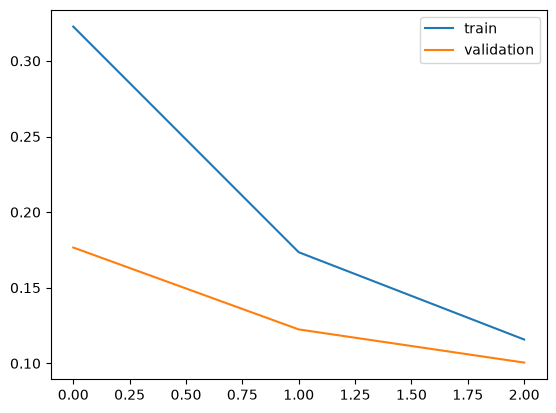

In [3]:
import tensorflow as tf
class ScaledTanh(tf.keras.layers.Layer):
    def call(self,x): return 1.7159*tf.math.tanh((2/3)*x)
(x,y),(xt,yt)=tf.keras.datasets.mnist.load_data()
x=x.astype("float32")/255; xt=xt.astype("float32")/255
m=tf.keras.Sequential([tf.keras.layers.Flatten(input_shape=(28,28)),tf.keras.layers.Dense(128),ScaledTanh(),tf.keras.layers.Dense(10)])
m.compile("adam",tf.keras.losses.SparseCategoricalCrossentropy(from_logits=True),metrics=["accuracy"])
h=m.fit(x,y,validation_split=.1,epochs=3)
print("test metrics",m.evaluate(xt,yt))
import matplotlib.pyplot as plt
plt.plot(h.history["loss"],label="train"); plt.plot(h.history["val_loss"],label="validation"); plt.legend(); plt.savefig("loss_curves.png")
